In [1]:
# Paths (relative to the repository root, so the notebooks run on any machine)
# Expected layout:  <repo>/notebooks/ (this file), <repo>/data/, <repo>/models/,
#                   <repo>/figures/, <repo>/results/, <repo>/feature_importance/
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FI_DIR = ROOT / "feature_importance"
for _d in (DATA_DIR, MODELS_DIR, FIG_DIR, RESULTS_DIR, FI_DIR):
    _d.mkdir(parents=True, exist_ok=True)


In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import joblib


In [3]:
import rdkit, mordred, sklearn, xgboost, catboost, lightgbm, shap
import sys
print(sys.version)
print("RDKit:", rdkit.__version__)
print("Mordred:", mordred.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("CatBoost:", catboost.__version__)
print("LightGBM:", lightgbm.__version__)
print("SHAP:", shap.__version__)

3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]
RDKit: 2026.03.3
Mordred: 1.2.0
scikit-learn: 1.9.0
XGBoost: 3.2.0
CatBoost: 1.2.10
LightGBM: 4.6.0
SHAP: 0.51.0


In [4]:
X_test = pd.read_csv(str(DATA_DIR / "X_test1.csv"))
y_test = pd.read_csv(str(DATA_DIR / "y_test1.csv")).squeeze()

best_cat = joblib.load(str(MODELS_DIR / "Best_CatBoost_Model1.pkl"))
best_lgbm = joblib.load(str(MODELS_DIR / "Best_LightGBM_Model1.pkl"))

pred_cat = best_cat.predict(X_test)
pred_lgbm = best_lgbm.predict(X_test)

rng = np.random.default_rng(42)
n = len(y_test)
n_boot = 5000

diffs = []
for _ in range(n_boot):
    idx = rng.integers(0, n, n)
    r2_cat = r2_score(y_test.iloc[idx], pred_cat[idx])
    r2_lgbm = r2_score(y_test.iloc[idx], pred_lgbm[idx])
    diffs.append(r2_cat - r2_lgbm)

diffs = np.array(diffs)
print("Mean R² difference (CatBoost - LightGBM):", diffs.mean())
print("95% CI:", np.percentile(diffs, [2.5, 97.5]))
print("Fraction of bootstrap samples where CatBoost > LightGBM:", (diffs > 0).mean())

Mean R² difference (CatBoost - LightGBM): 0.0019933445708925513
95% CI: [-0.0023316   0.00636448]
Fraction of bootstrap samples where CatBoost > LightGBM: 0.813


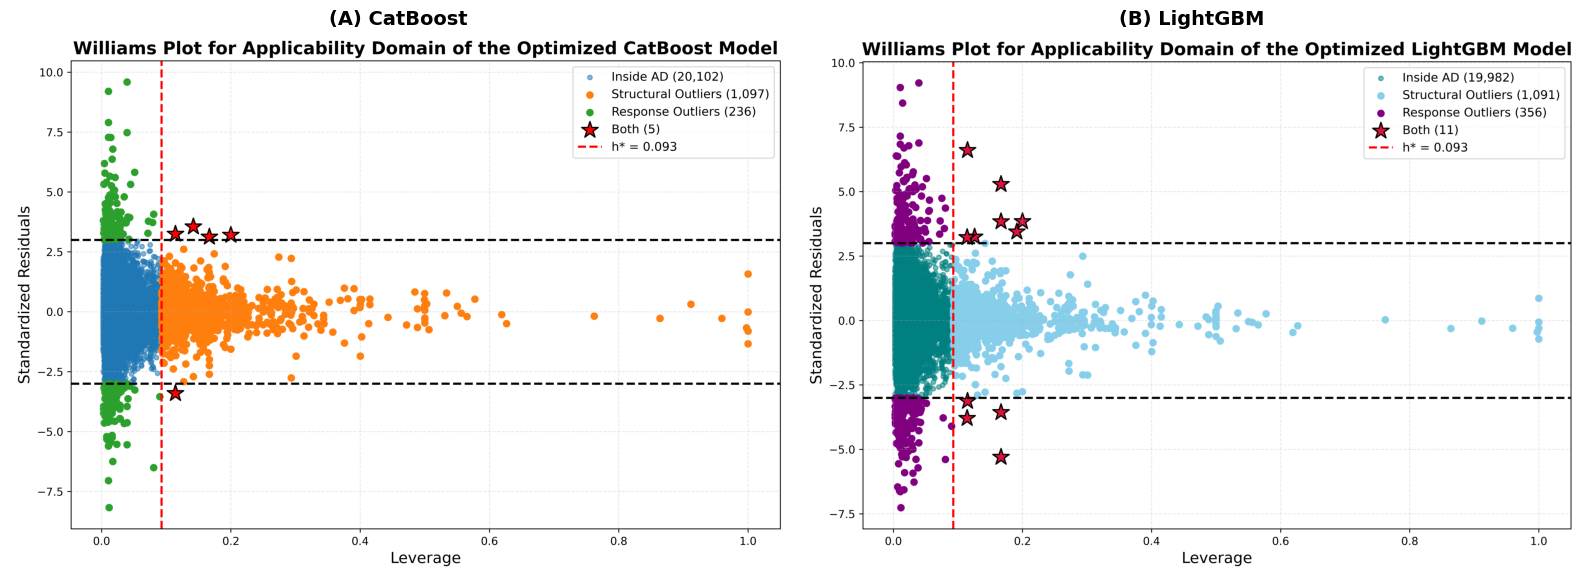

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Williams_Plot_Final_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Williams_Plot_Final_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Williams_Plot_Combined_1.png"), dpi=800, bbox_inches="tight")
plt.show()

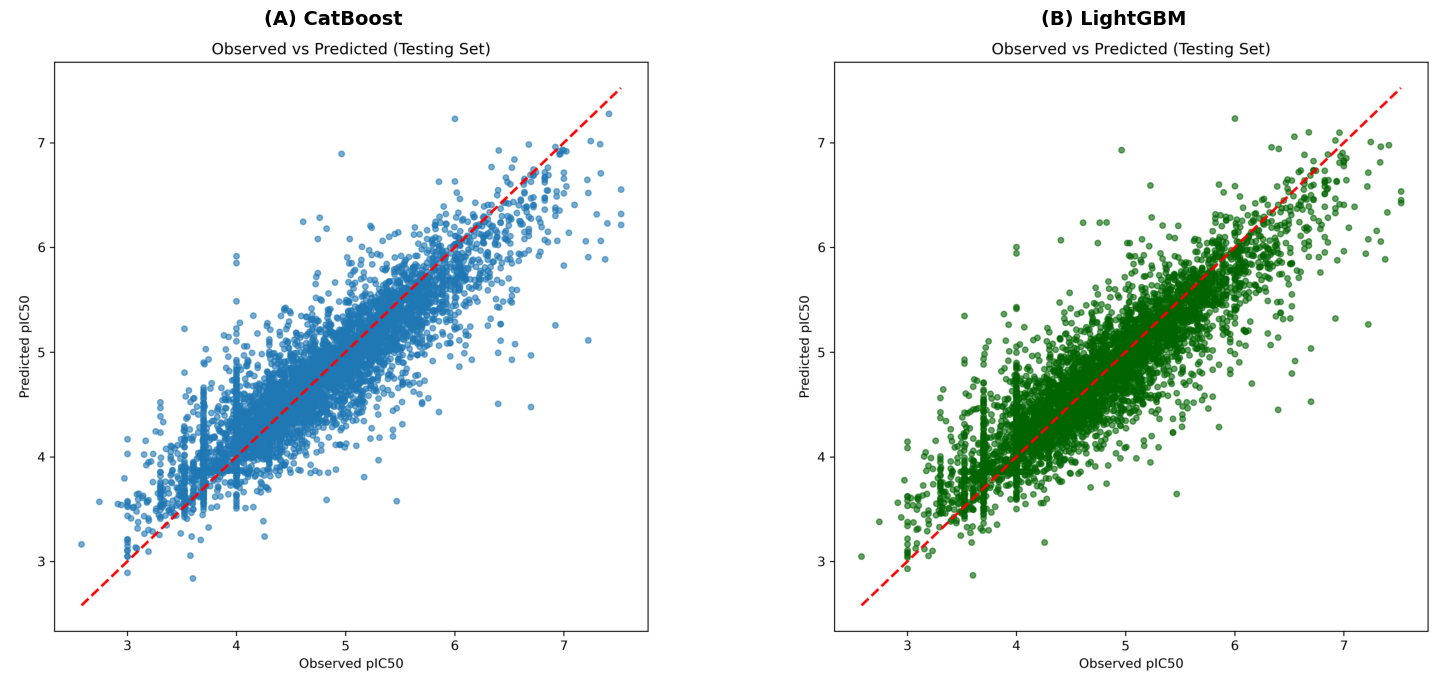

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Observed_vs_Predicted_Testing_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Observed_vs_Predicted_Testing_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Observed_vs_Predicted_Testing_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

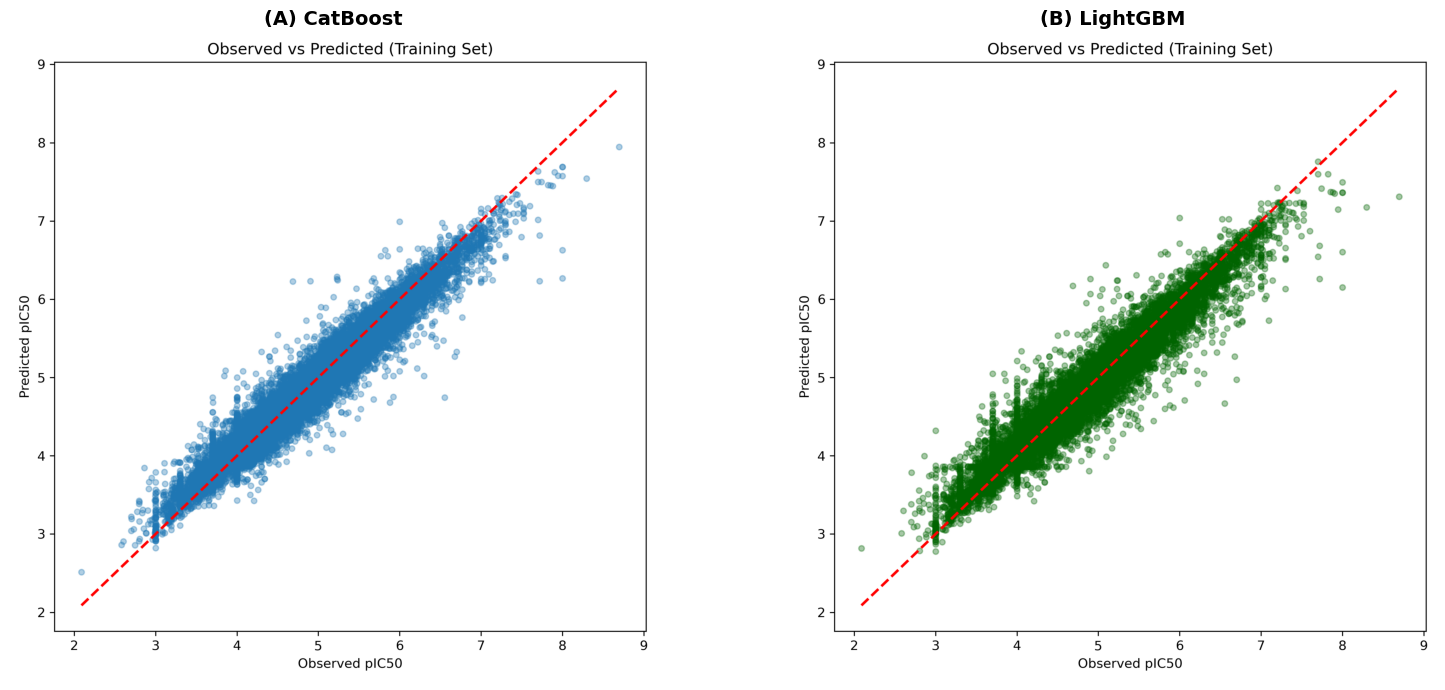

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Observed_vs_Predicted_Training_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Observed_vs_Predicted_Training_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Observed_vs_Predicted_Training_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

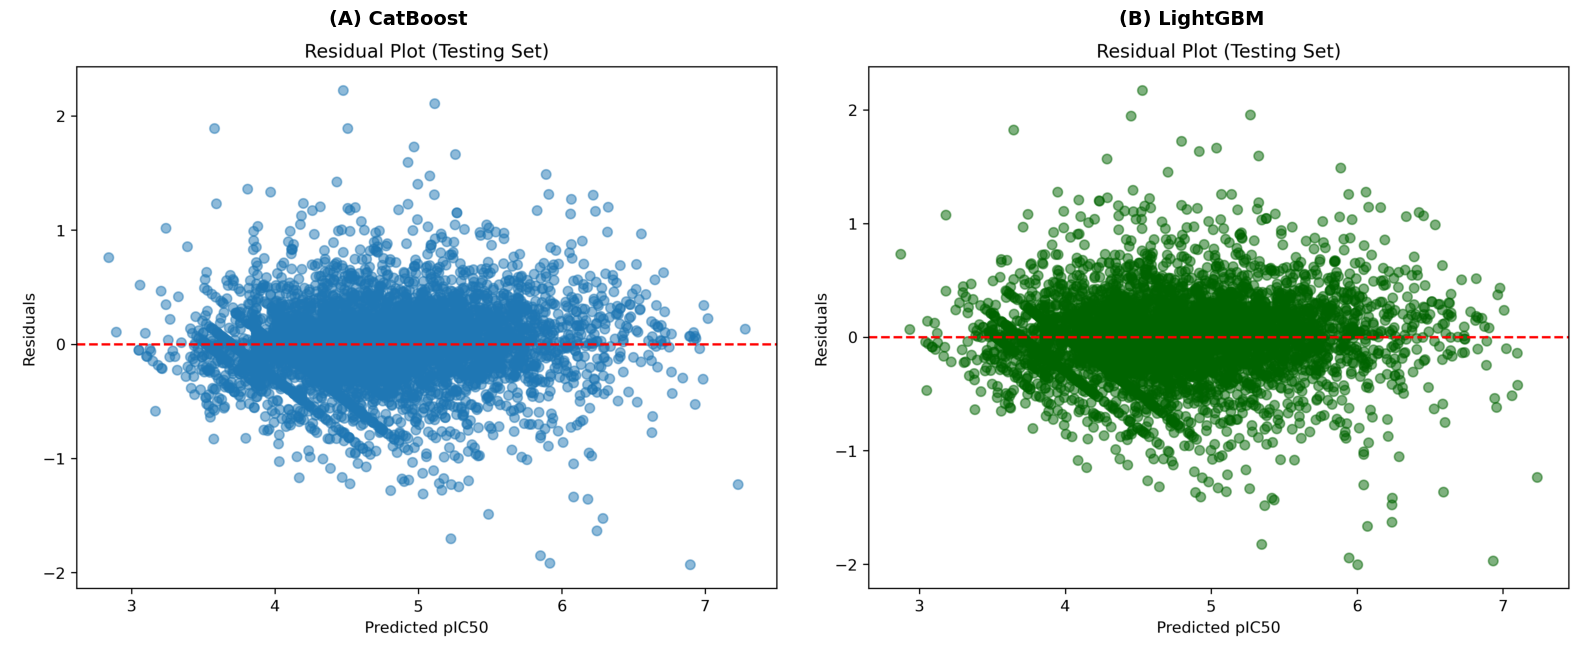

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Testing_Residual_Plot_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Testing_Residual_Plot_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Testing_Residual_Plot_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

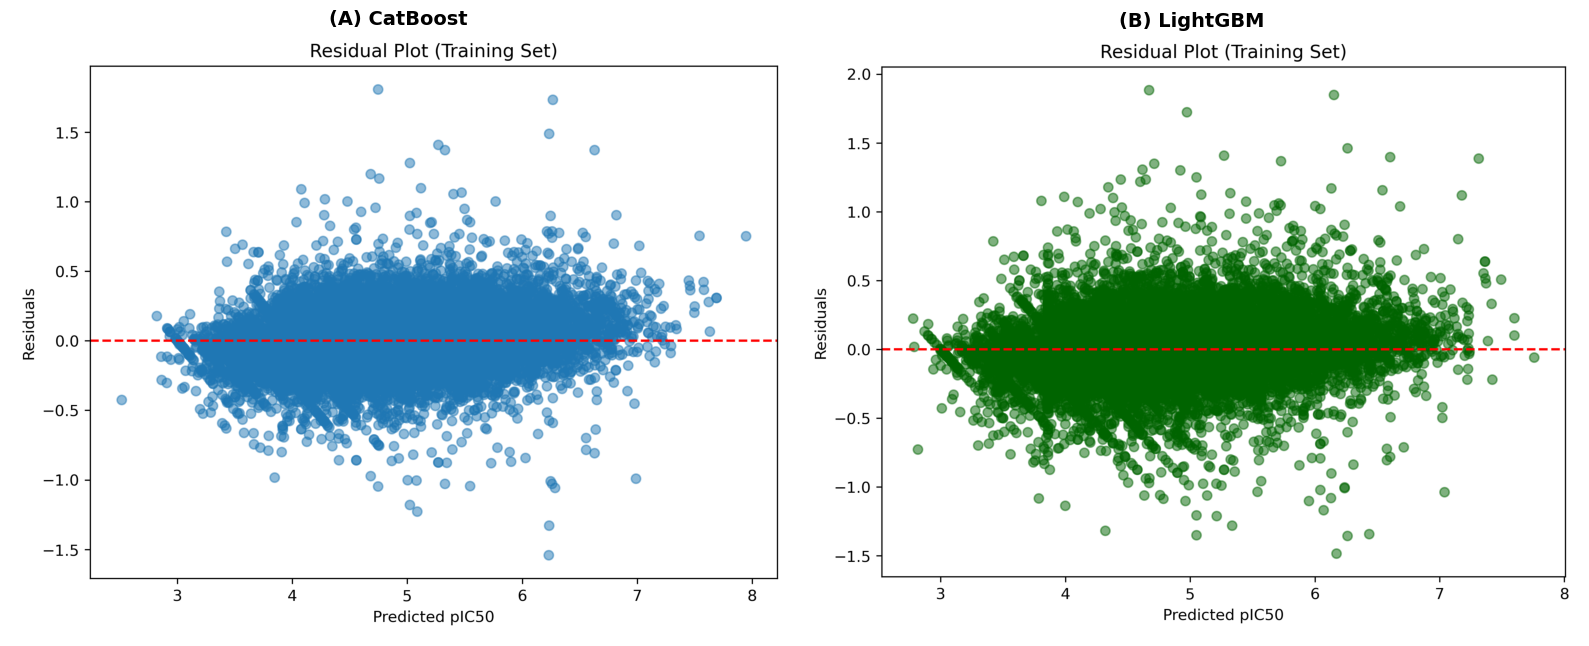

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Training_Residual_Plot_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Training_Residual_Plot_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Training_Residual_Plot_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

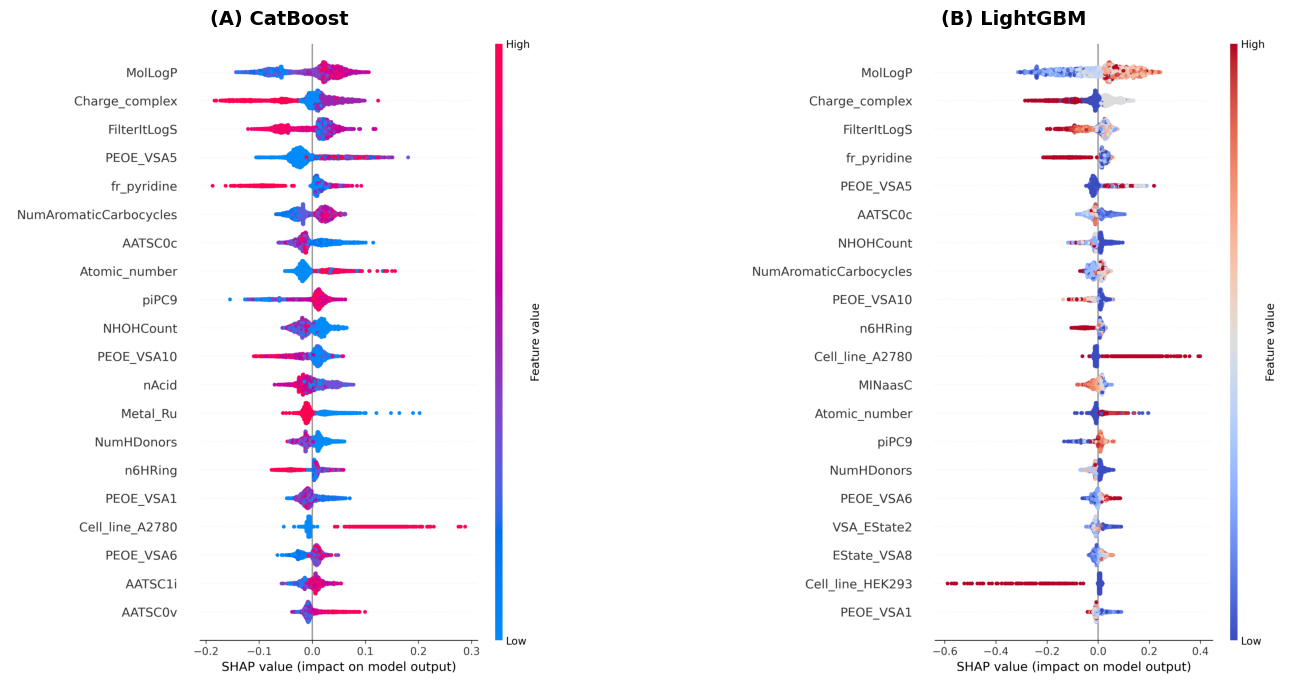

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "SHAP_Beeswarm_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "SHAP_Beeswarm_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "SHAP_Beeswarm_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

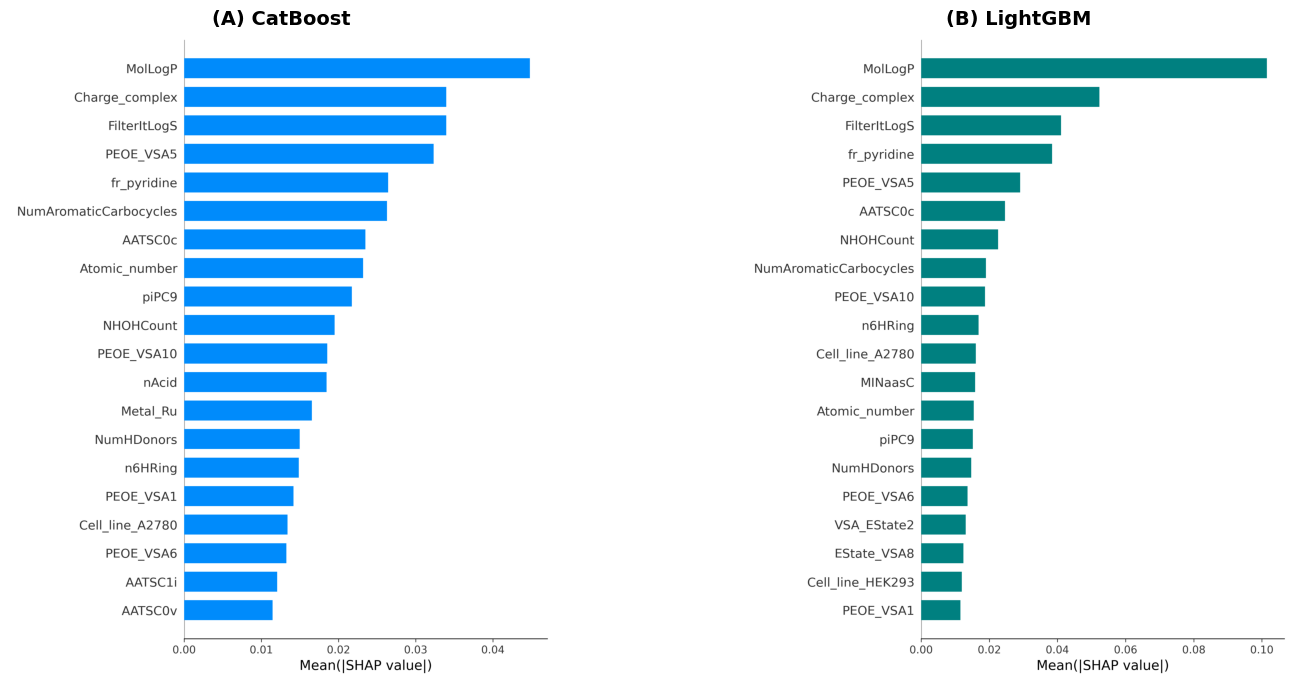

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "SHAP_Bar_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "SHAP_Bar_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "SHAP_Bar_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

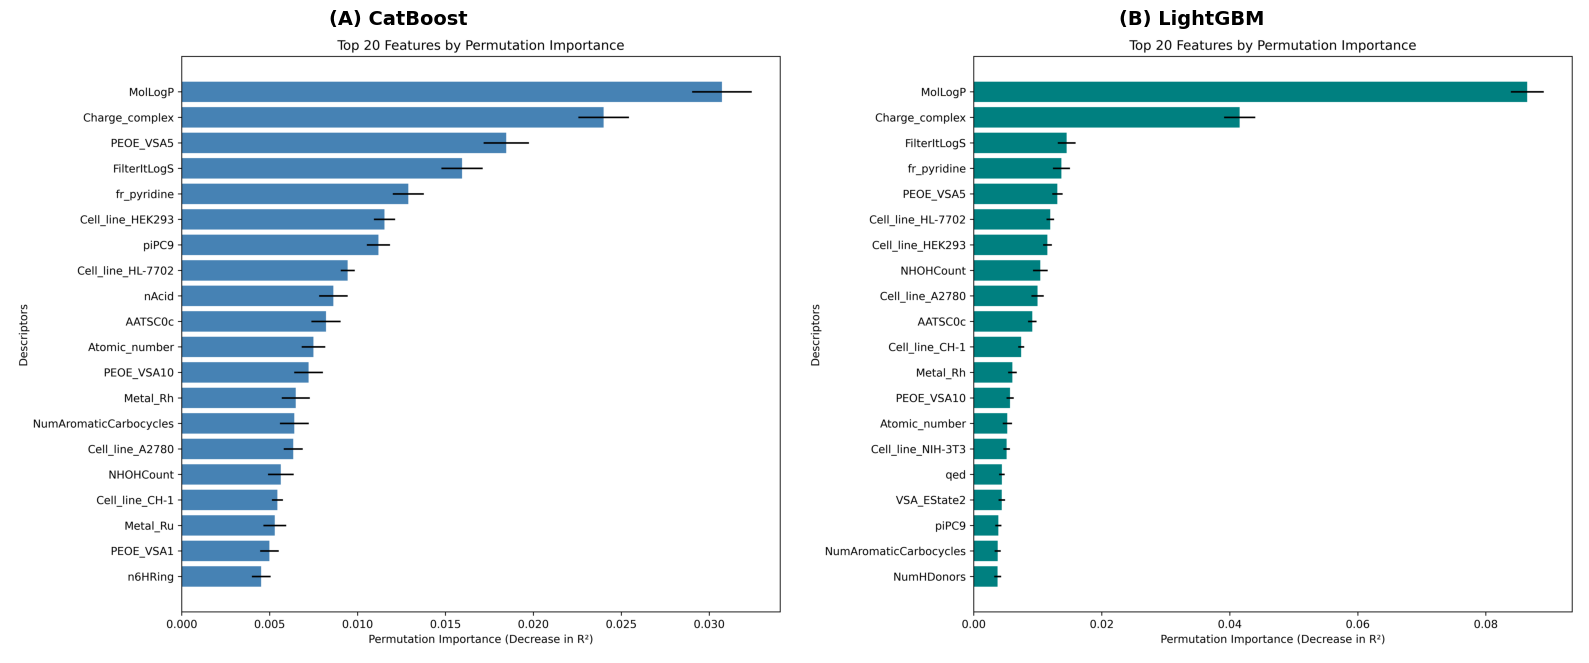

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Permutation_Importance_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Permutation_Importance_2.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Permutation_Importance_Combined.png"), dpi=600, bbox_inches="tight")
plt.show()

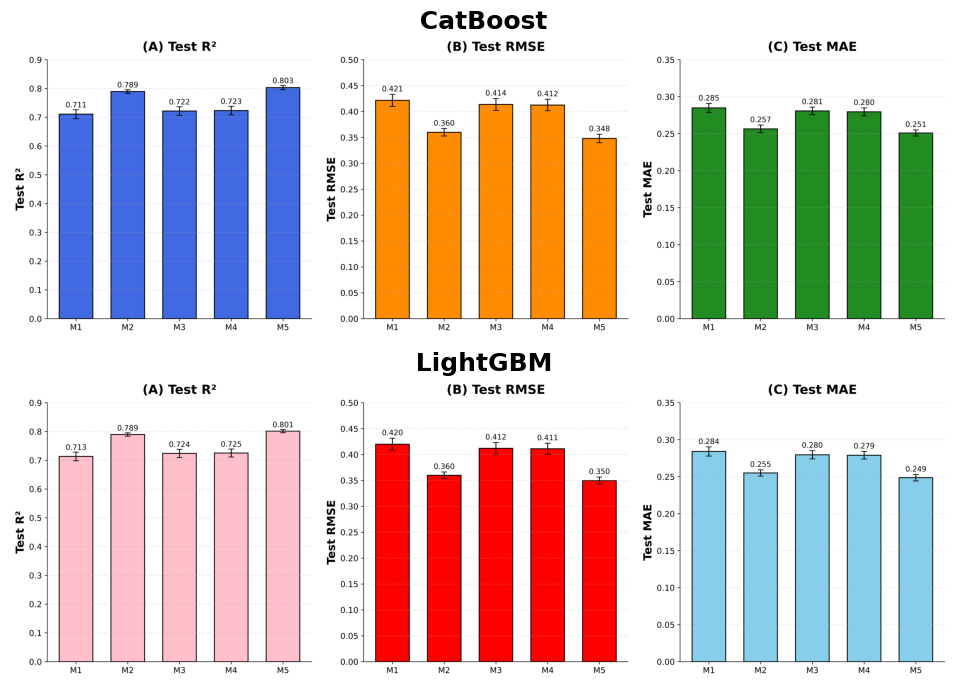

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(16, 7))

img_cat = mpimg.imread(str(FIG_DIR / "Ablation_Study_horizontal_withoutspines_1.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "Ablation_Study_horizontal_withoutspines_3.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title(" CatBoost", fontsize=18, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title(" LightGBM", fontsize=18, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "Ablation_Study_horizontal_withoutspines_combined.png"), dpi=600, bbox_inches="tight")
plt.show()

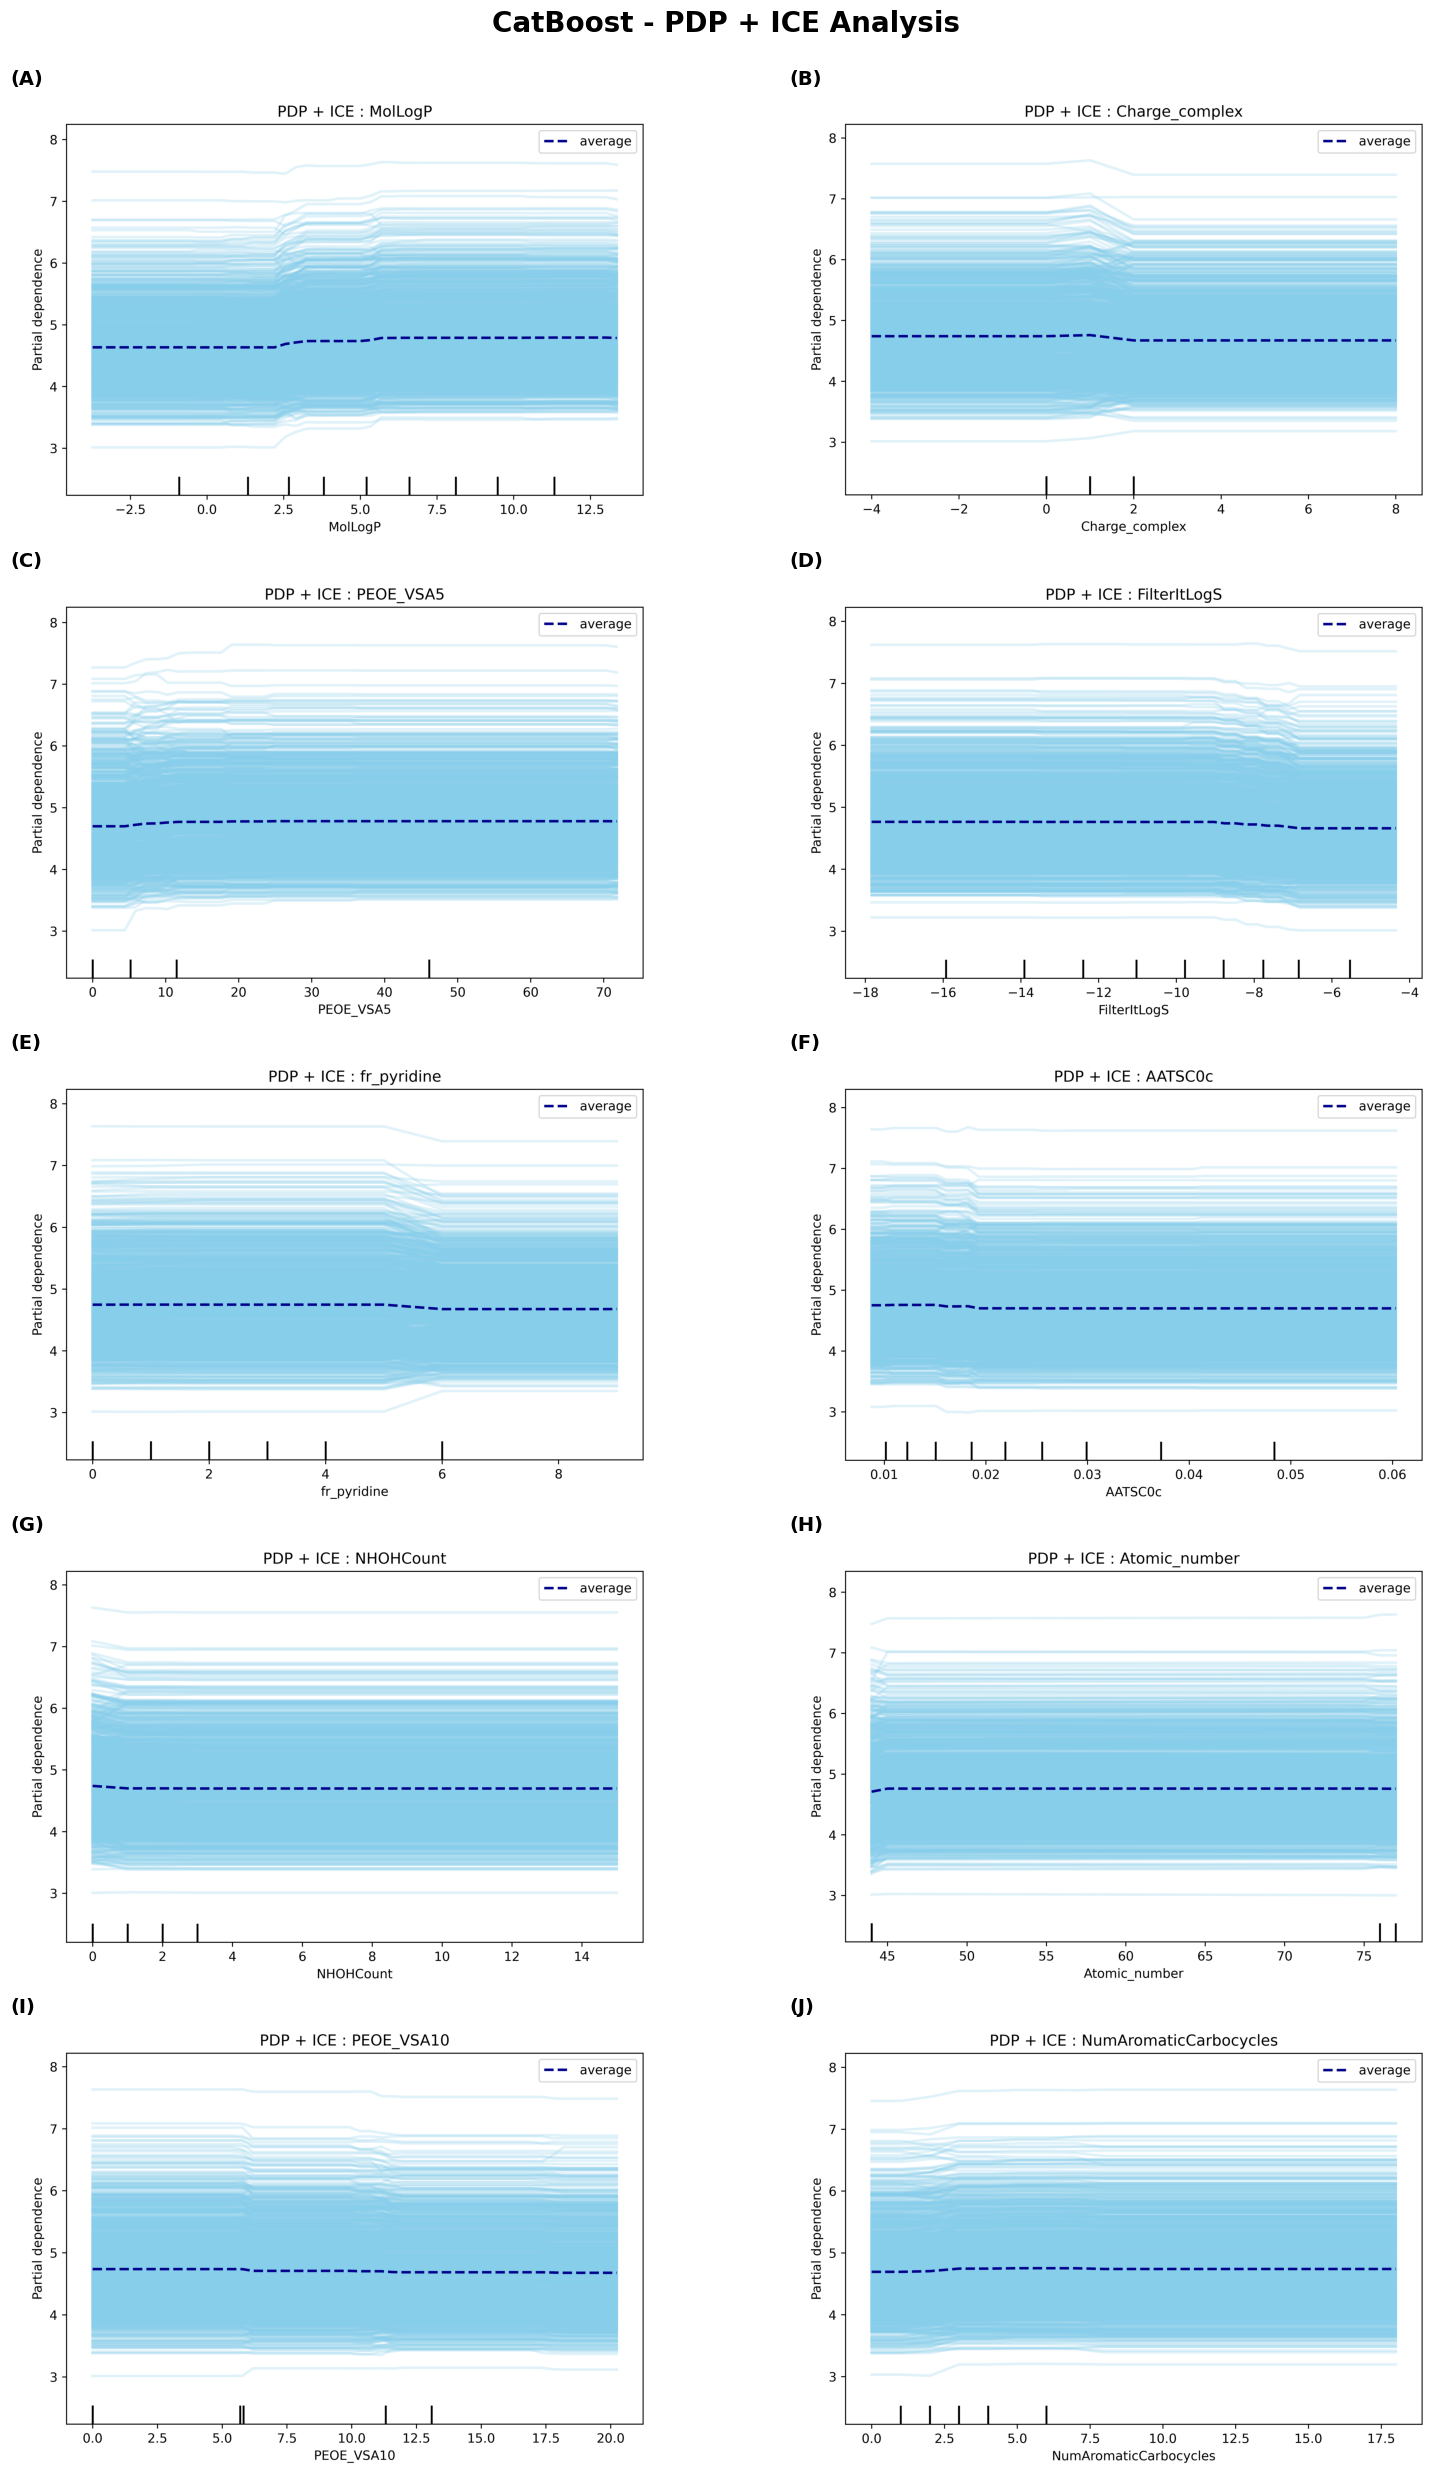

In [14]:
image_paths = [
    str(FIG_DIR / "1_PDP_MolLogP.png"),
    str(FIG_DIR / "1_PDP_Charge_complex.png"),
    str(FIG_DIR / "1_PDP_PEOE_VSA5.png"),
    str(FIG_DIR / "1_PDP_FilterItLogS.png"),
    str(FIG_DIR / "1_PDP_fr_pyridine.png"),
    str(FIG_DIR / "1_PDP_AATSC0c.png"),
    str(FIG_DIR / "1_PDP_NHOHCount.png"),
    str(FIG_DIR / "1_PDP_Atomic_number.png"),
    str(FIG_DIR / "1_PDP_PEOE_VSA10.png"),
    str(FIG_DIR / "1_PDP_NumAromaticCarbocycles.png")
]

labels = [
    "(A)", "(B)", "(C)", "(D)", "(E)",
    "(F)", "(G)", "(H)", "(I)", "(J)"
]

fig, axes = plt.subplots(
    5,
    2,
    figsize=(16, 25)
)

axes = axes.flatten()

fig.suptitle(
    "CatBoost - PDP + ICE Analysis",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

for ax, image_path, label in zip(axes, image_paths, labels):

    img = mpimg.imread(image_path)

    ax.imshow(img)
    ax.axis("off")

    # Panel label outside the image
    ax.text(
        -0.02,
        1.02,
        label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.01,
    wspace=0.03,
    hspace=0.08
)

plt.savefig(
    str(FIG_DIR / "PDP_ICE_Combined_catboost.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

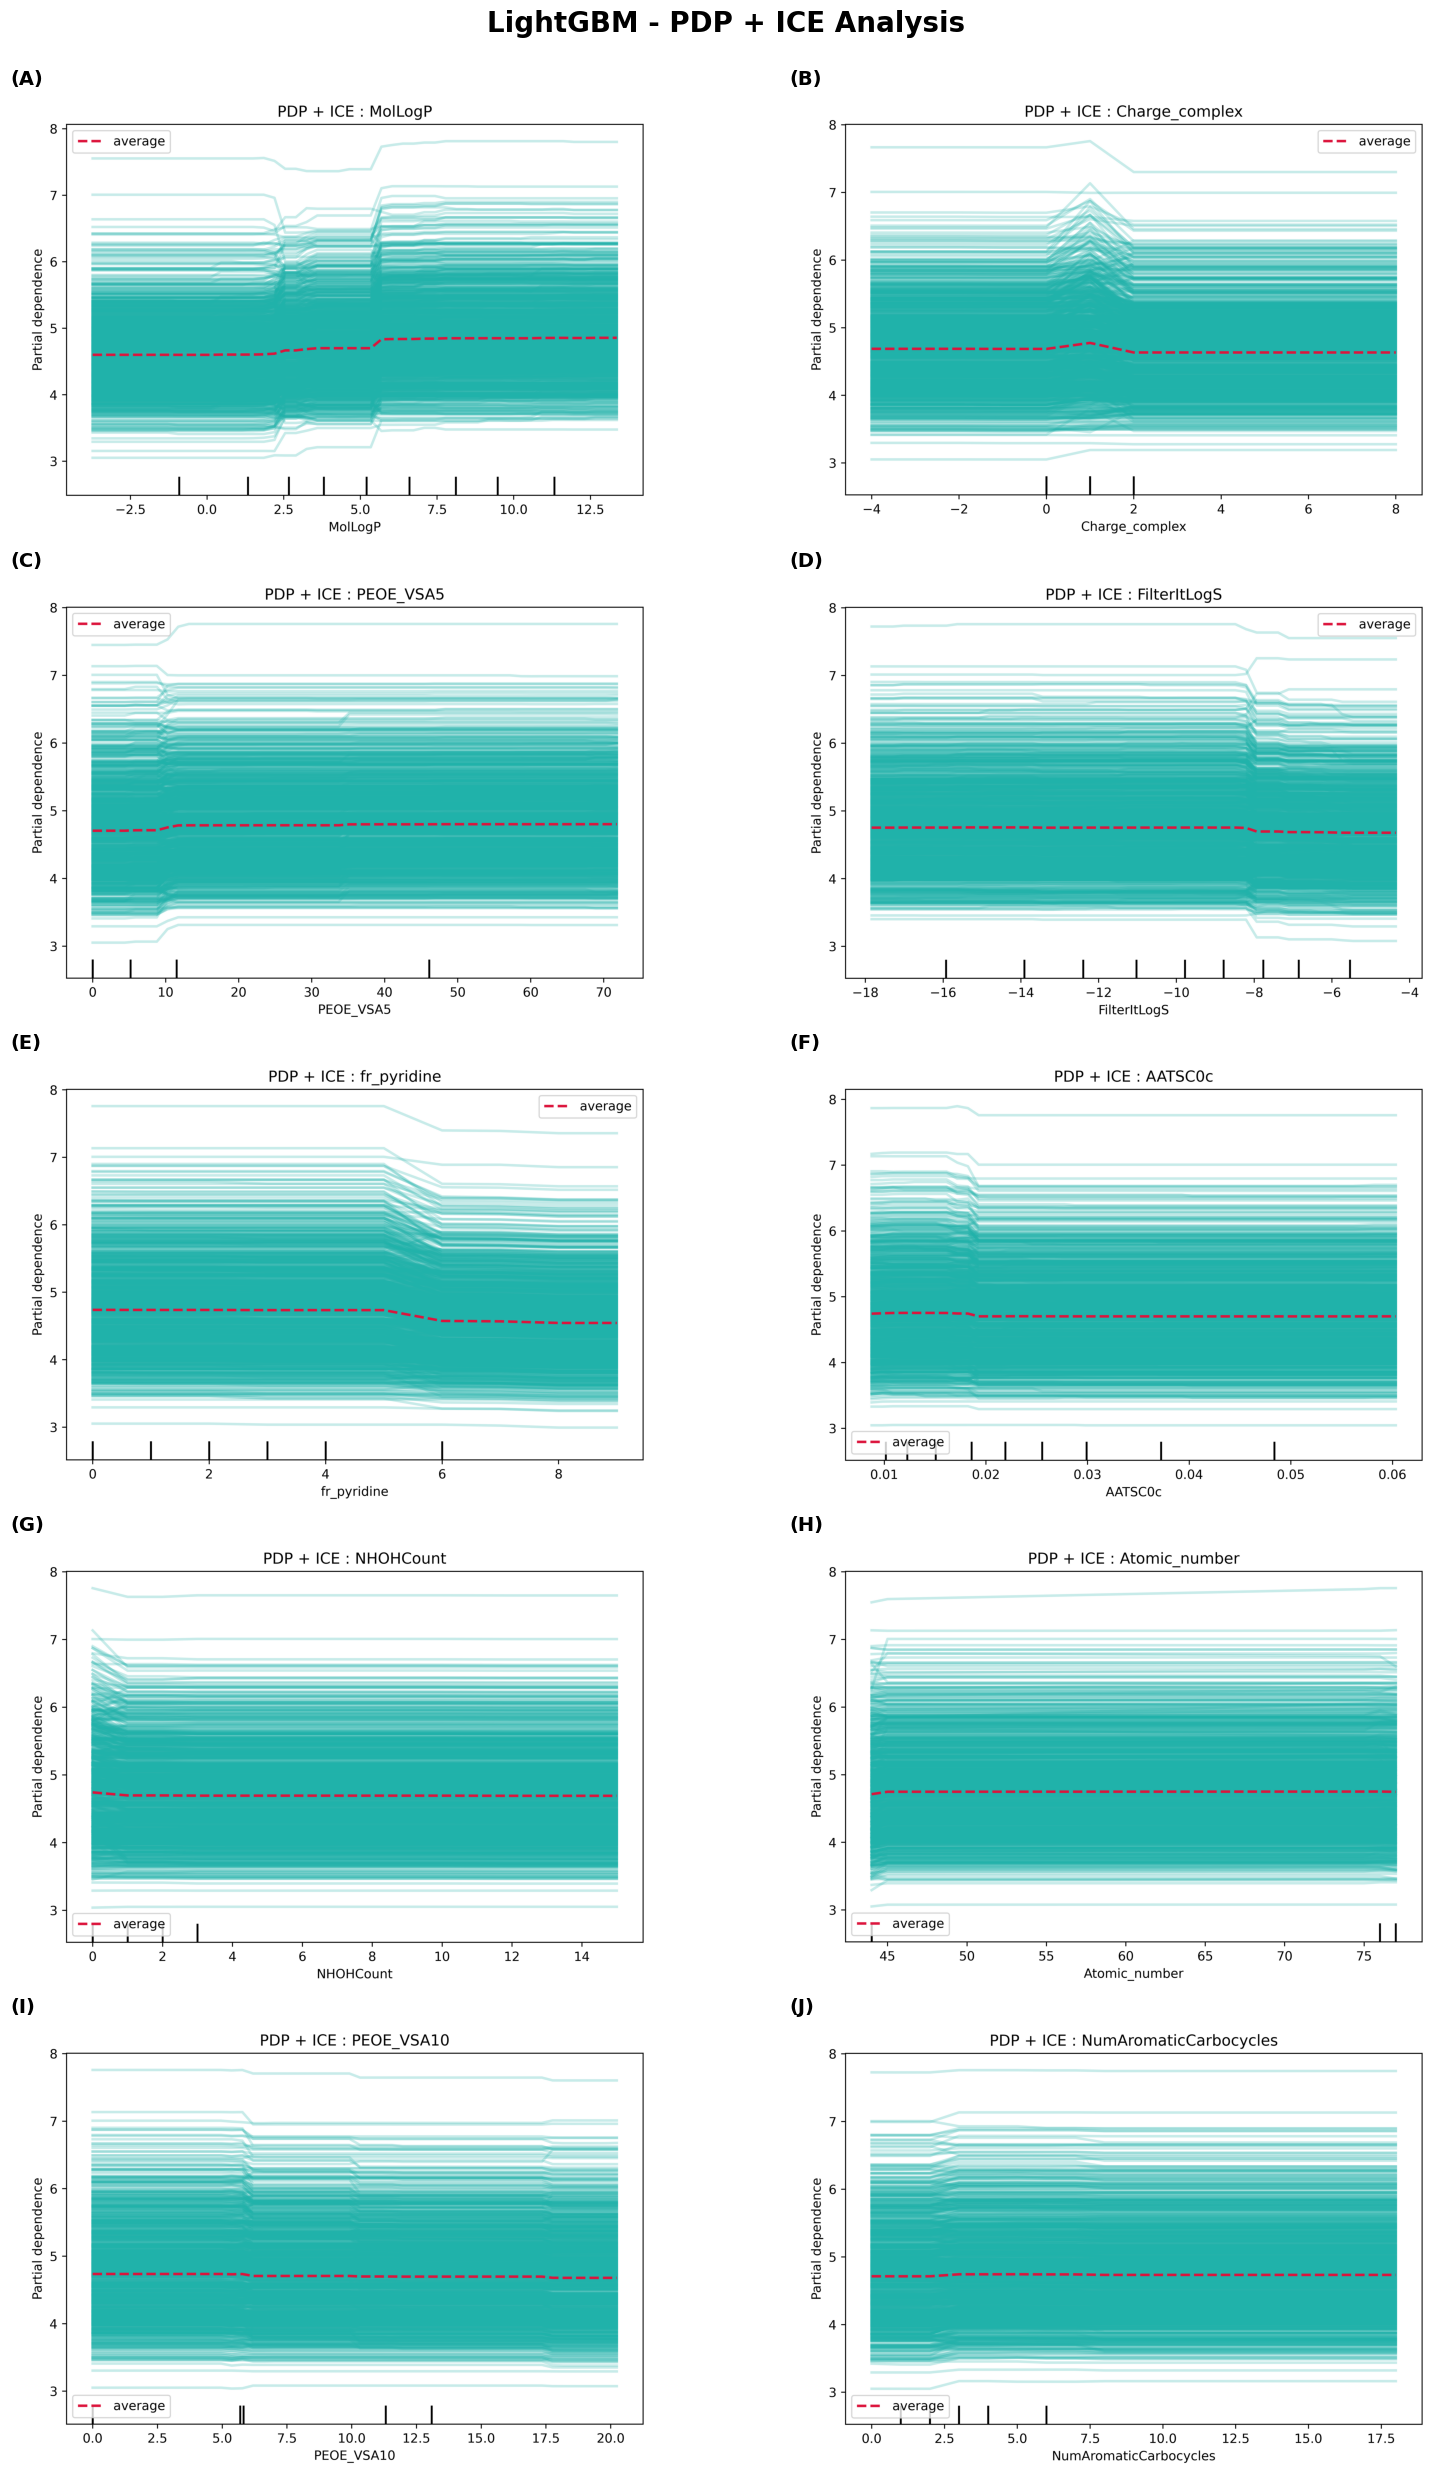

In [15]:
image_paths = [
    str(FIG_DIR / "2_PDP_MolLogP.png"),
    str(FIG_DIR / "2_PDP_Charge_complex.png"),
    str(FIG_DIR / "2_PDP_PEOE_VSA5.png"),
    str(FIG_DIR / "2_PDP_FilterItLogS.png"),
    str(FIG_DIR / "2_PDP_fr_pyridine.png"),
    str(FIG_DIR / "2_PDP_AATSC0c.png"),
    str(FIG_DIR / "2_PDP_NHOHCount.png"),
    str(FIG_DIR / "2_PDP_Atomic_number.png"),
    str(FIG_DIR / "2_PDP_PEOE_VSA10.png"),
    str(FIG_DIR / "2_PDP_NumAromaticCarbocycles.png")
]

labels = [
    "(A)", "(B)", "(C)", "(D)", "(E)",
    "(F)", "(G)", "(H)", "(I)", "(J)"
]

fig, axes = plt.subplots(
    5,
    2,
    figsize=(16, 25)
)

axes = axes.flatten()

fig.suptitle(
    "LightGBM - PDP + ICE Analysis",
    fontsize=20,
    fontweight="bold",
    y=0.995
)


for ax, image_path, label in zip(axes, image_paths, labels):

    img = mpimg.imread(image_path)

    ax.imshow(img)
    ax.axis("off")

    # Panel label outside the image
    ax.text(
        -0.02,
        1.02,
        label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.01,
    wspace=0.03,
    hspace=0.08
)

plt.savefig(
    str(FIG_DIR / "PDP_ICE_Combined_lightgbm.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

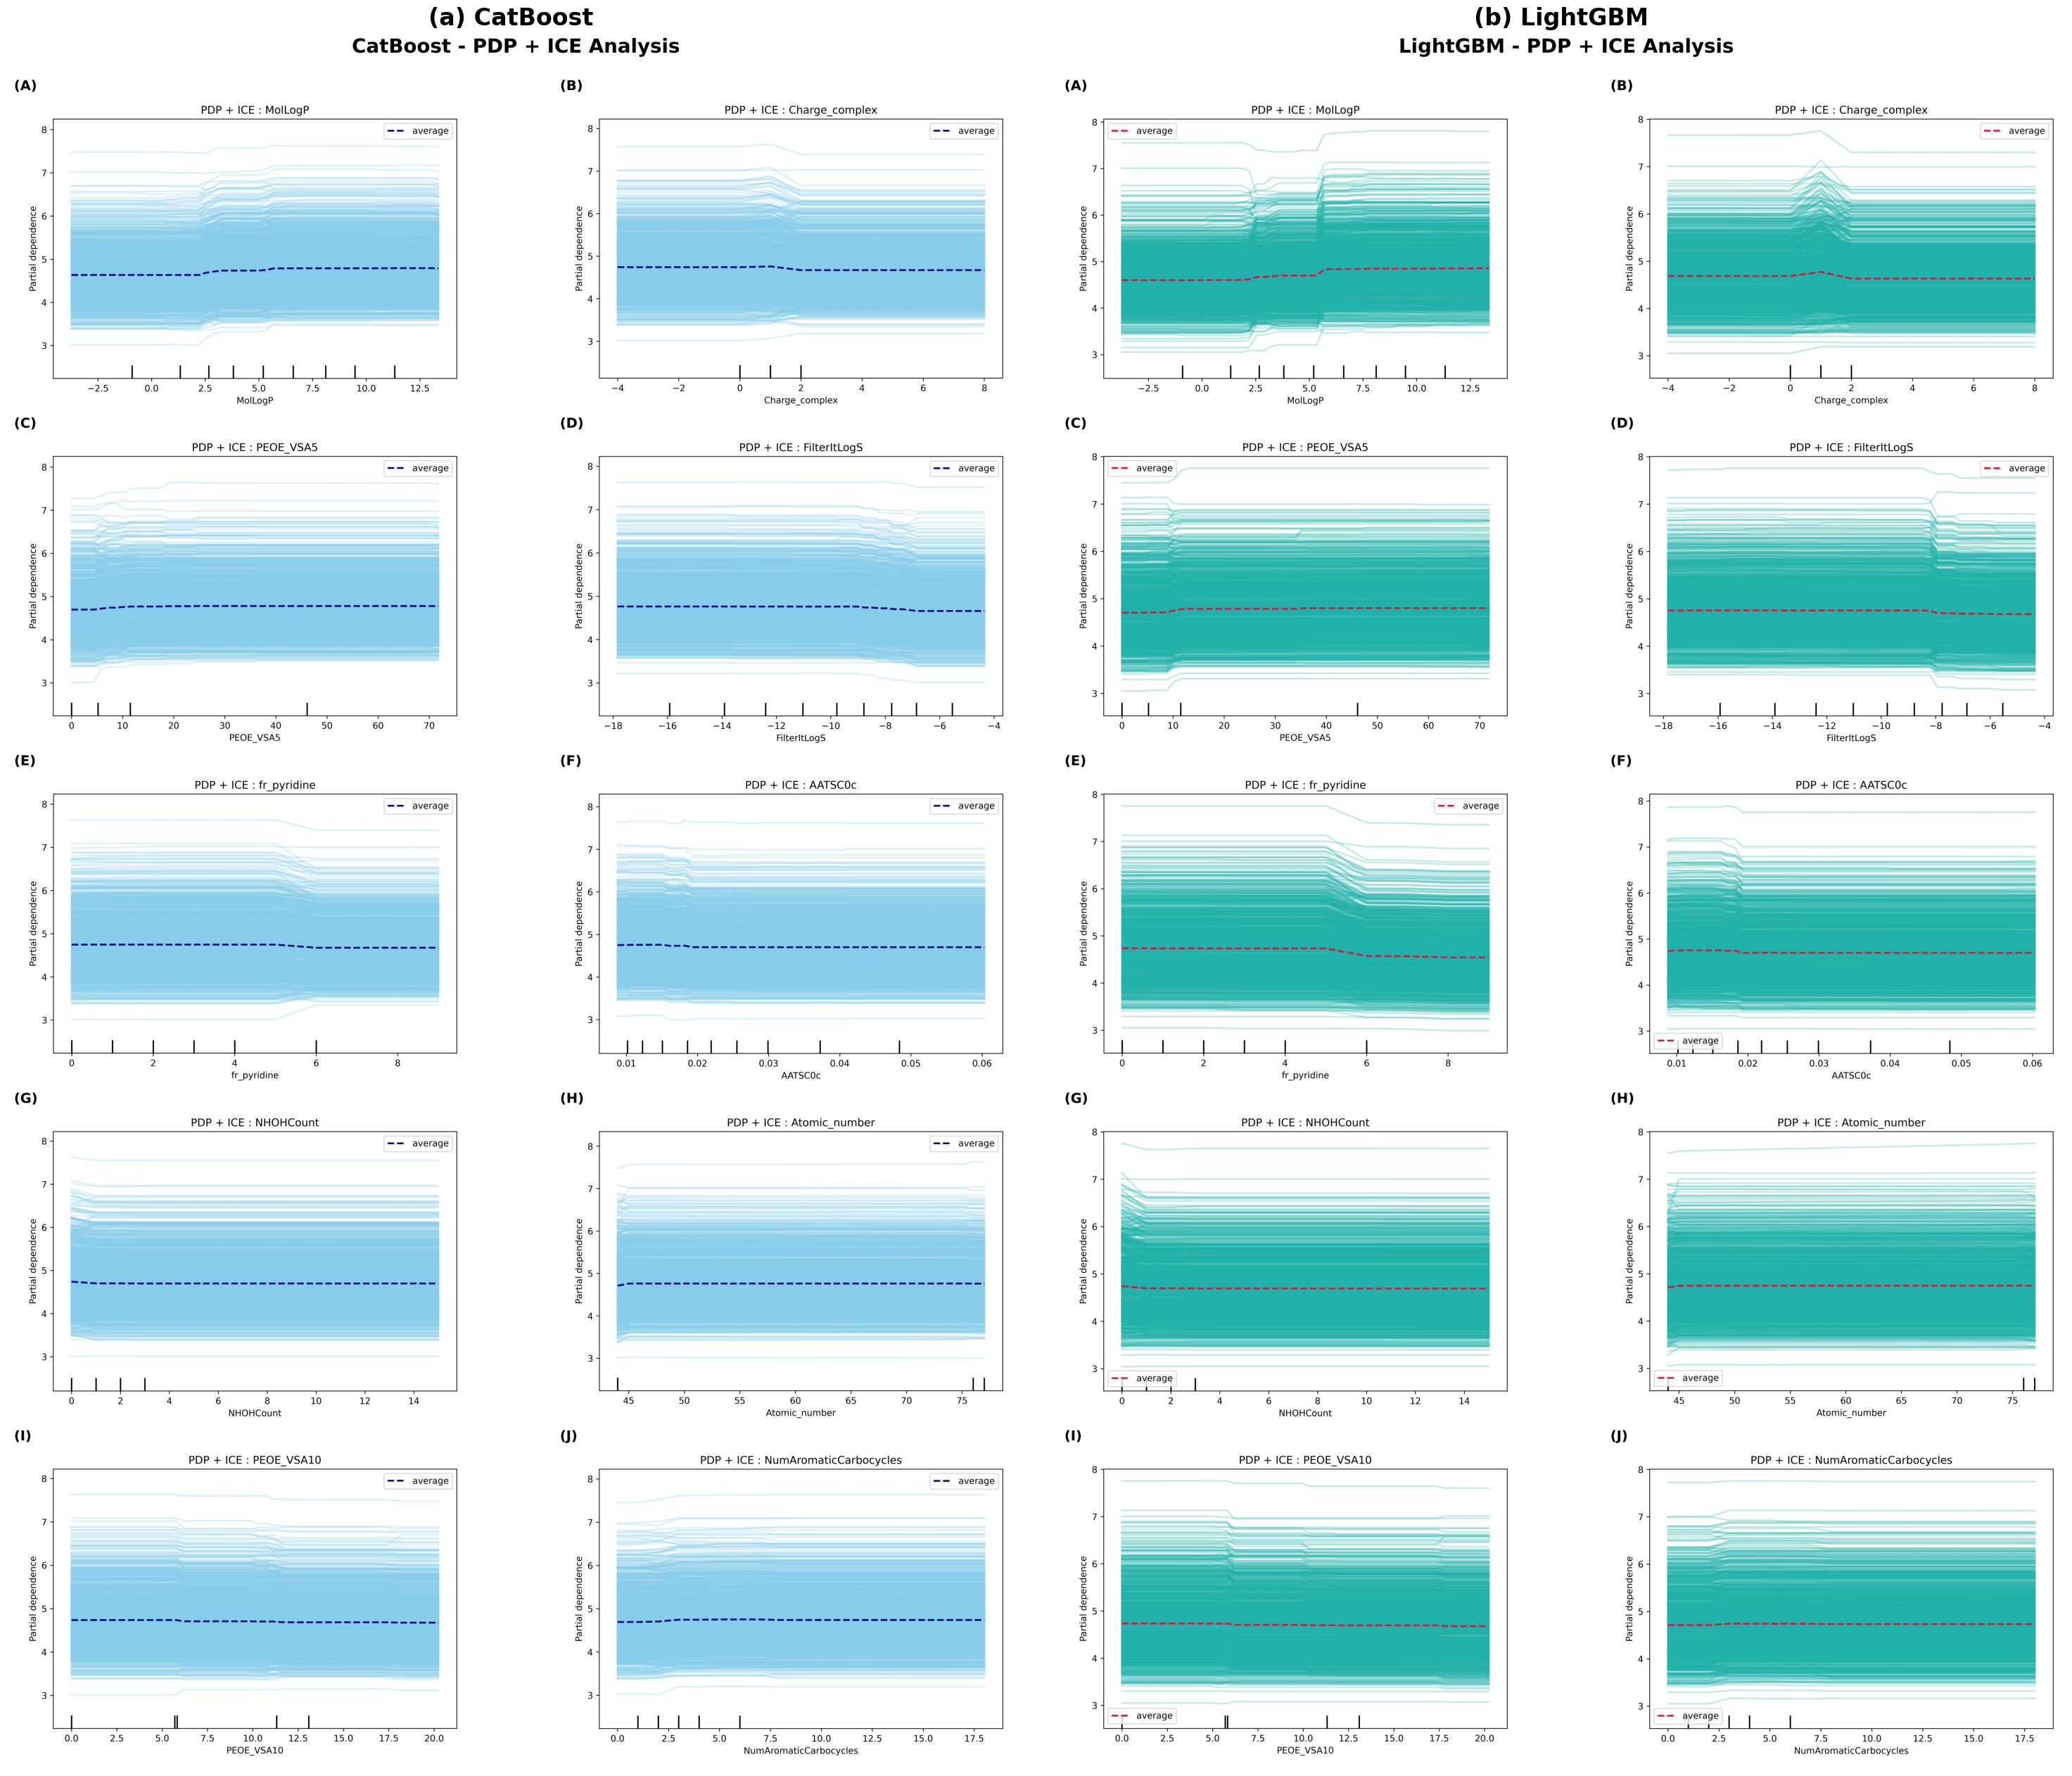

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(30, 25))

img_cat = mpimg.imread(str(FIG_DIR / "PDP_ICE_Combined_catboost.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "PDP_ICE_Combined_lightgbm.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(a) CatBoost", fontsize=24, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(b) LightGBM", fontsize=24, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "PDP_ICE_Combined_of_Models.png"), dpi=600, bbox_inches="tight")
plt.show()

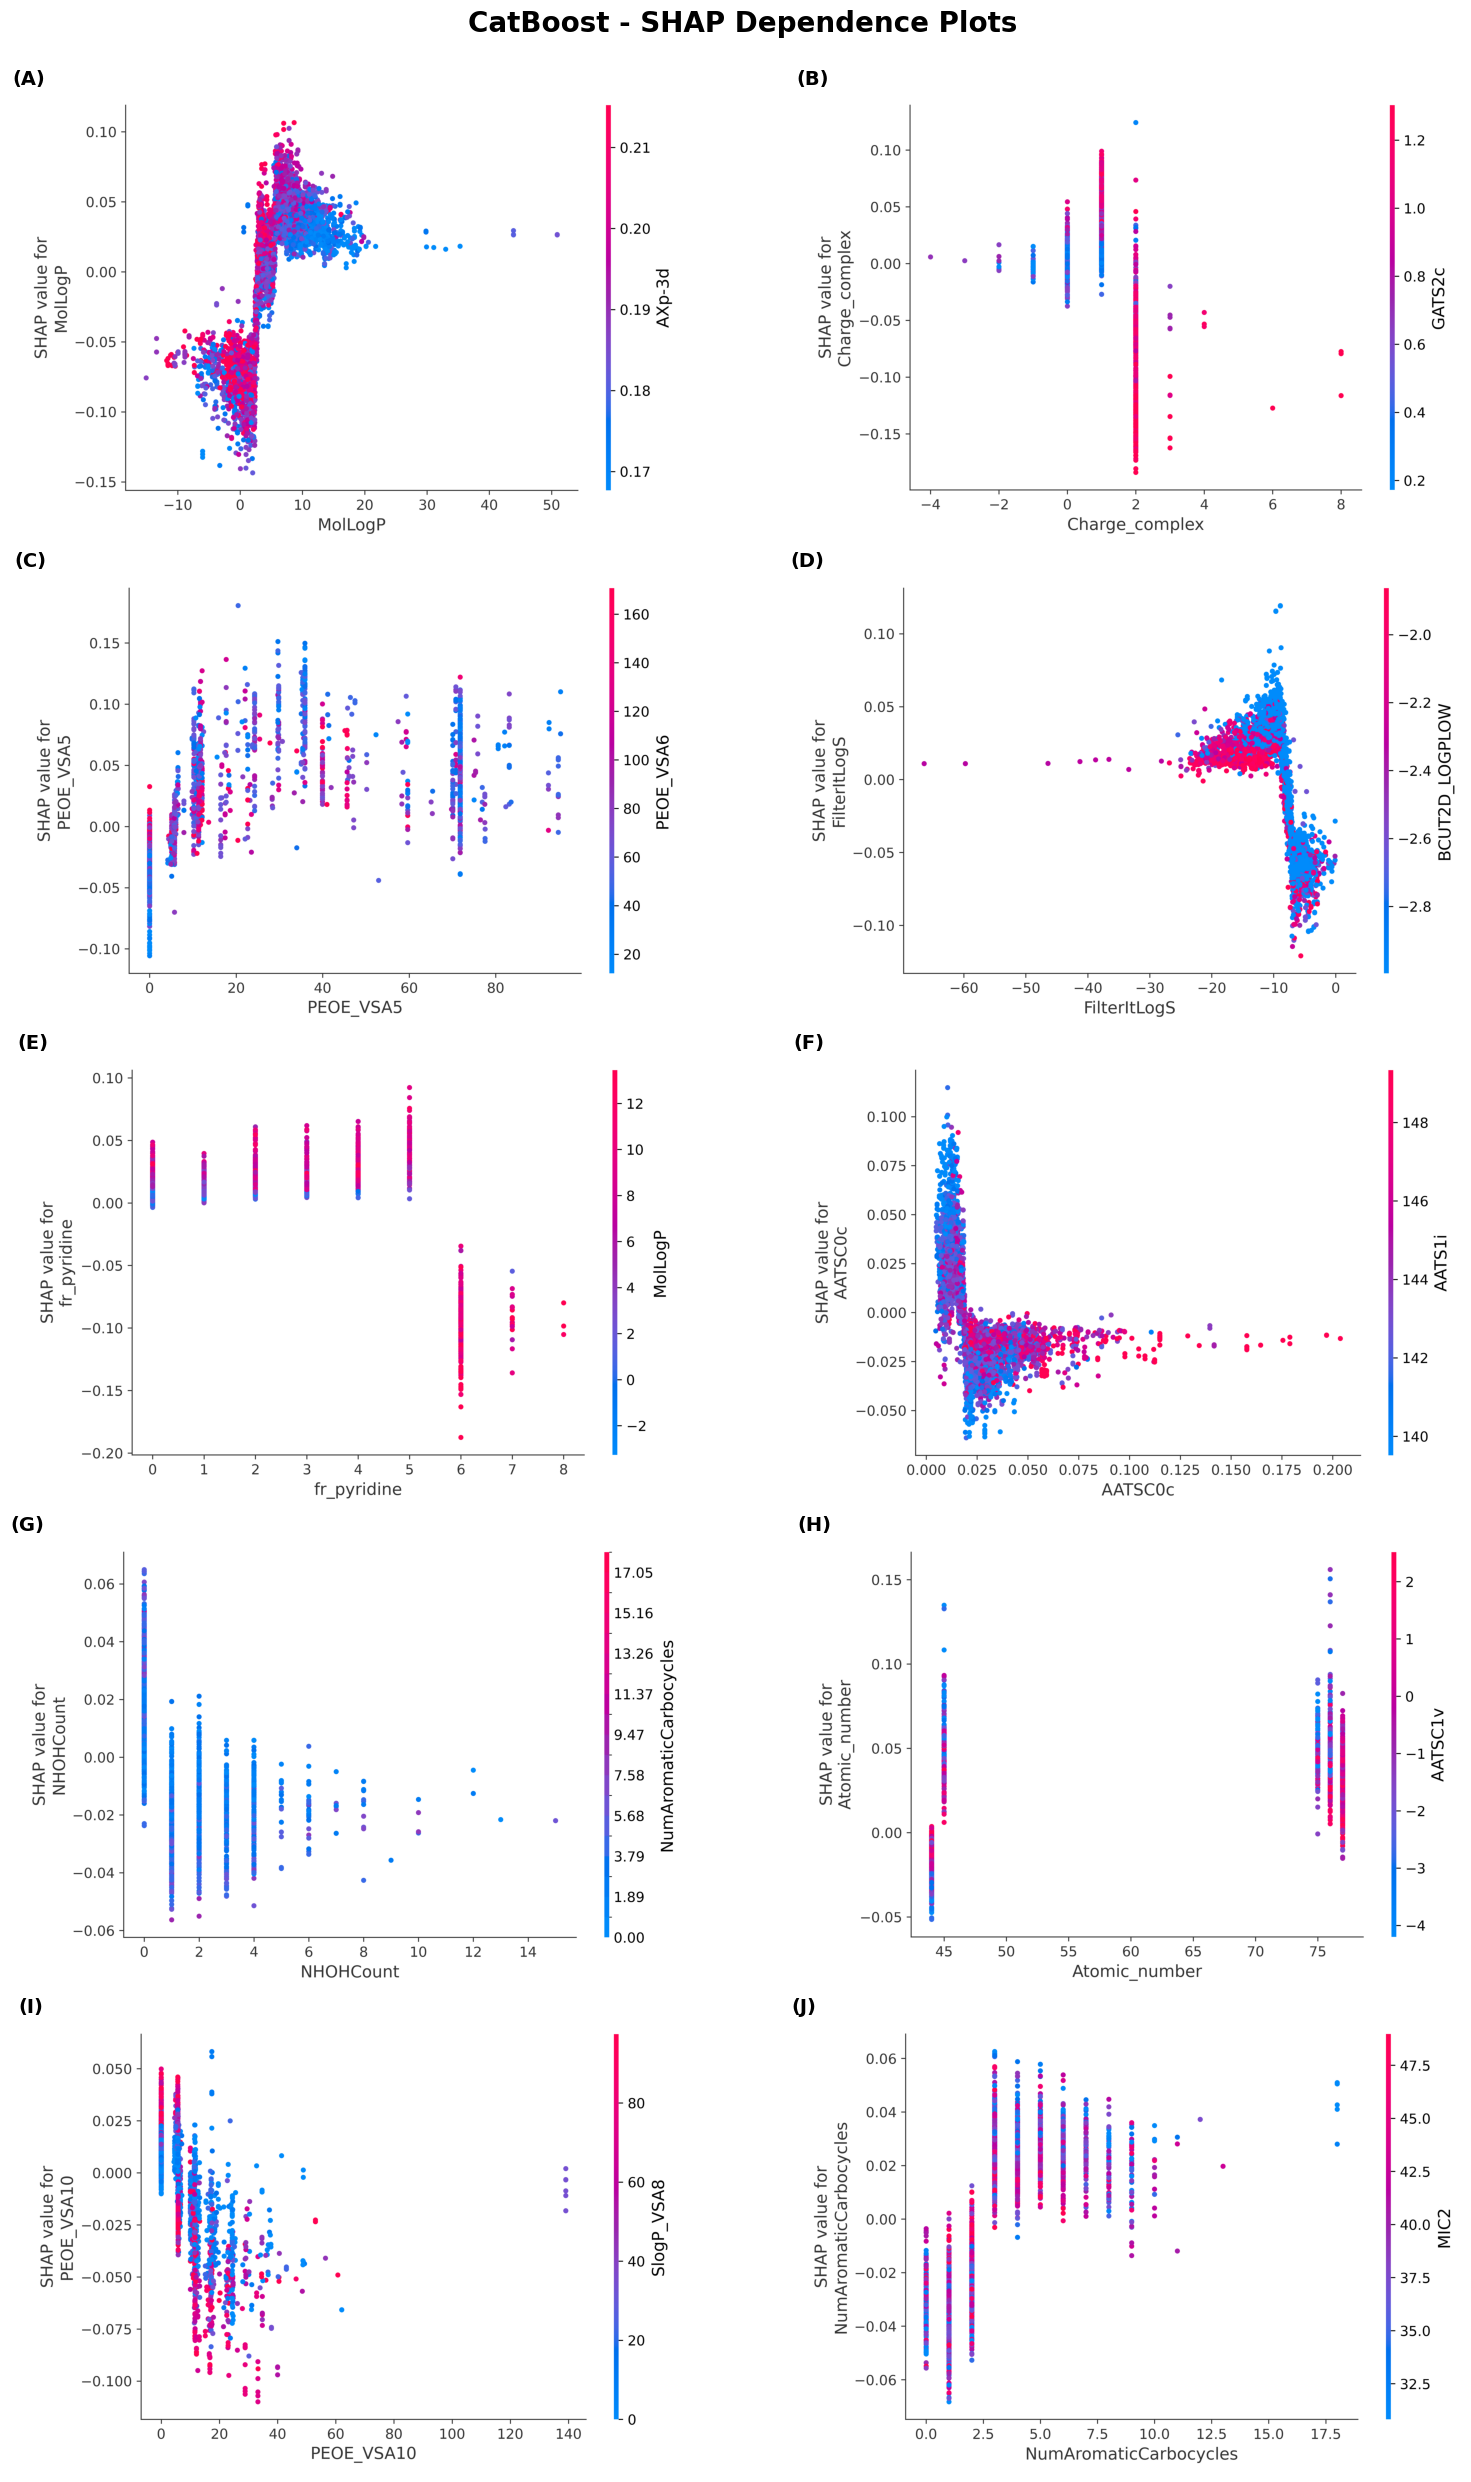

In [17]:
image_paths = [
    str(FIG_DIR / "1_SHAP_Dependence_MolLogP.png"),
    str(FIG_DIR / "1_SHAP_Dependence_Charge_complex.png"),
    str(FIG_DIR / "1_SHAP_Dependence_PEOE_VSA5.png"),
    str(FIG_DIR / "1_SHAP_Dependence_FilterItLogS.png"),
    str(FIG_DIR / "1_SHAP_Dependence_fr_pyridine.png"),
    str(FIG_DIR / "1_SHAP_Dependence_AATSC0c.png"),
    str(FIG_DIR / "1_SHAP_Dependence_NHOHCount.png"),
    str(FIG_DIR / "1_SHAP_Dependence_Atomic_number.png"),
    str(FIG_DIR / "1_SHAP_Dependence_PEOE_VSA10.png"),
    str(FIG_DIR / "1_SHAP_Dependence_NumAromaticCarbocycles.png")
]

labels = [
    "(A)", "(B)", "(C)", "(D)", "(E)",
    "(F)", "(G)", "(H)", "(I)", "(J)"
]

fig, axes = plt.subplots(
    5,
    2,
    figsize=(16, 25)
)

axes = axes.flatten()


fig.suptitle(
    "CatBoost - SHAP Dependence Plots",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

for ax, image_path, label in zip(axes, image_paths, labels):

    img = mpimg.imread(image_path)

    ax.imshow(img)
    ax.axis("off")

    # Panel label outside the image
    ax.text(
        -0.02,
        1.02,
        label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.01,
    wspace=0.03,
    hspace=0.08
)

plt.savefig(
    str(FIG_DIR / "SHAP_Dependence_combined_catboost.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

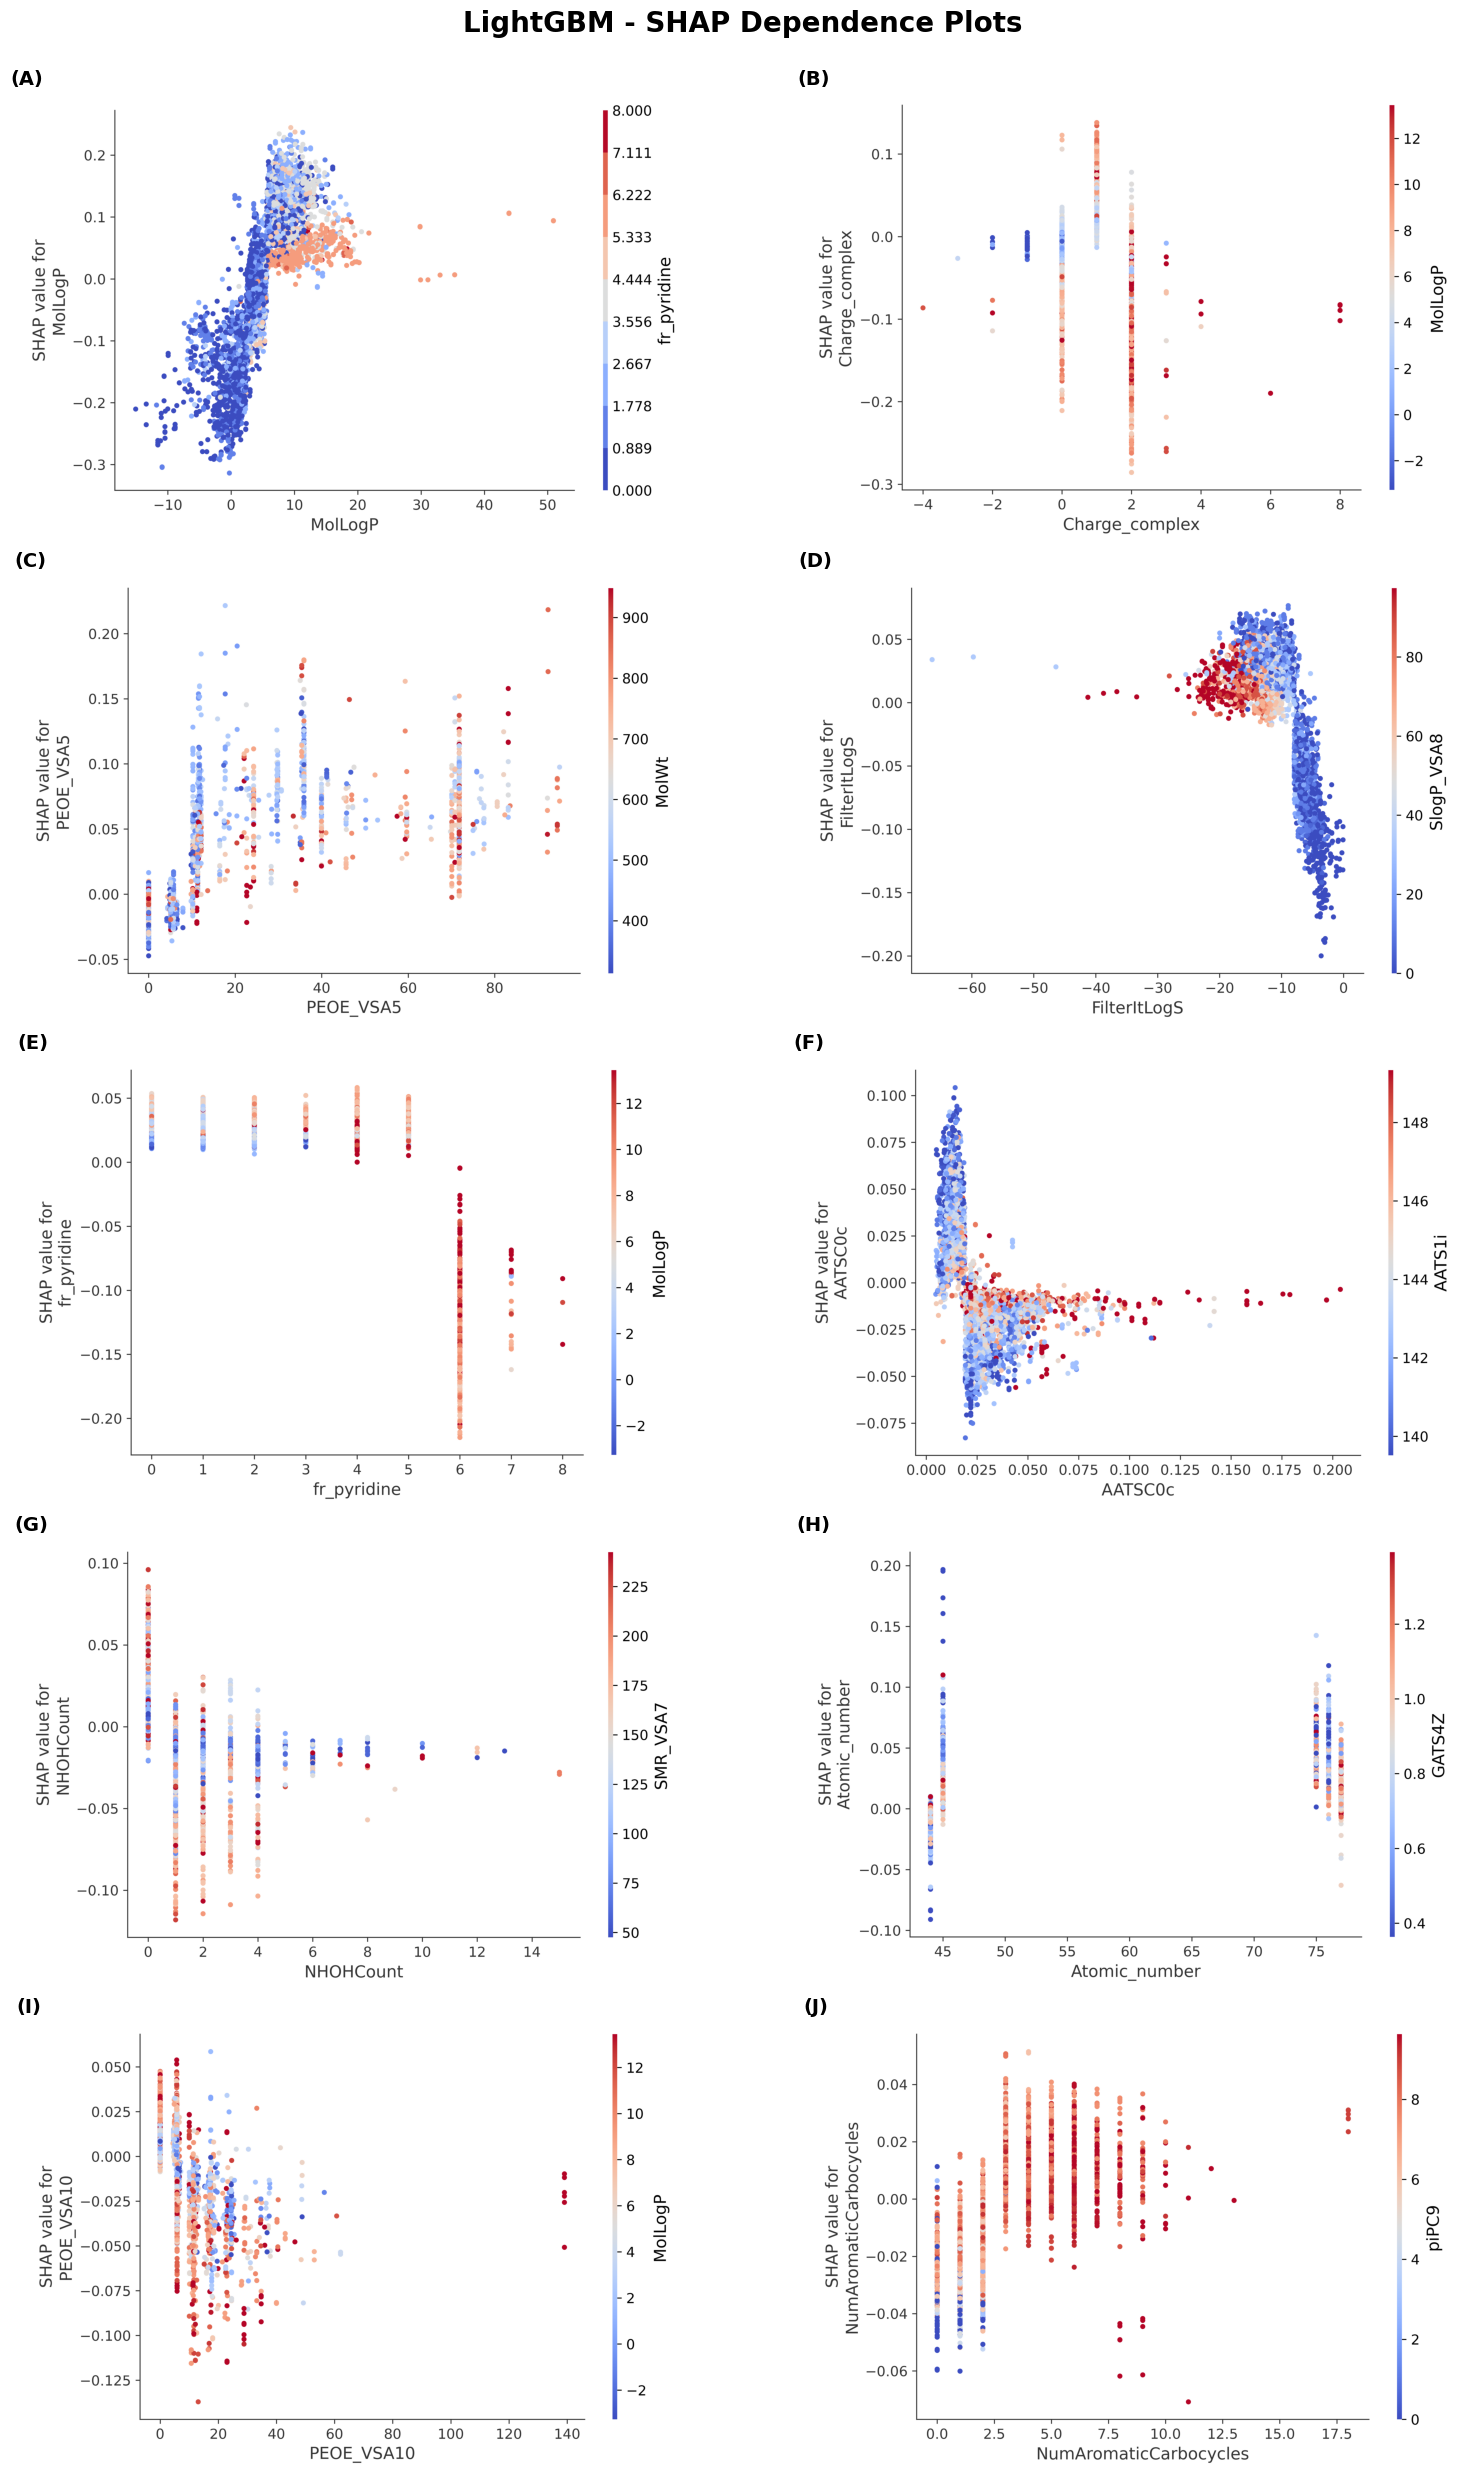

In [18]:
image_paths = [
    str(FIG_DIR / "2_SHAP_Dependence_MolLogP.png"),
    str(FIG_DIR / "2_SHAP_Dependence_Charge_complex.png"),
    str(FIG_DIR / "2_SHAP_Dependence_PEOE_VSA5.png"),
    str(FIG_DIR / "2_SHAP_Dependence_FilterItLogS.png"),
    str(FIG_DIR / "2_SHAP_Dependence_fr_pyridine.png"),
    str(FIG_DIR / "2_SHAP_Dependence_AATSC0c.png"),
    str(FIG_DIR / "2_SHAP_Dependence_NHOHCount.png"),
    str(FIG_DIR / "2_SHAP_Dependence_Atomic_number.png"),
    str(FIG_DIR / "2_SHAP_Dependence_PEOE_VSA10.png"),
    str(FIG_DIR / "2_SHAP_Dependence_NumAromaticCarbocycles.png")
]

labels = [
    "(A)", "(B)", "(C)", "(D)", "(E)",
    "(F)", "(G)", "(H)", "(I)", "(J)"
]

fig, axes = plt.subplots(
    5,
    2,
    figsize=(16, 25)
)

axes = axes.flatten()

fig.suptitle(
    "LightGBM - SHAP Dependence Plots",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

for ax, image_path, label in zip(axes, image_paths, labels):

    img = mpimg.imread(image_path)

    ax.imshow(img)
    ax.axis("off")

    # Panel label outside the image
    ax.text(
        -0.02,
        1.02,
        label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.01,
    wspace=0.03,
    hspace=0.08
)

plt.savefig(
    str(FIG_DIR / "SHAP_Dependence_combined_lightgbm.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

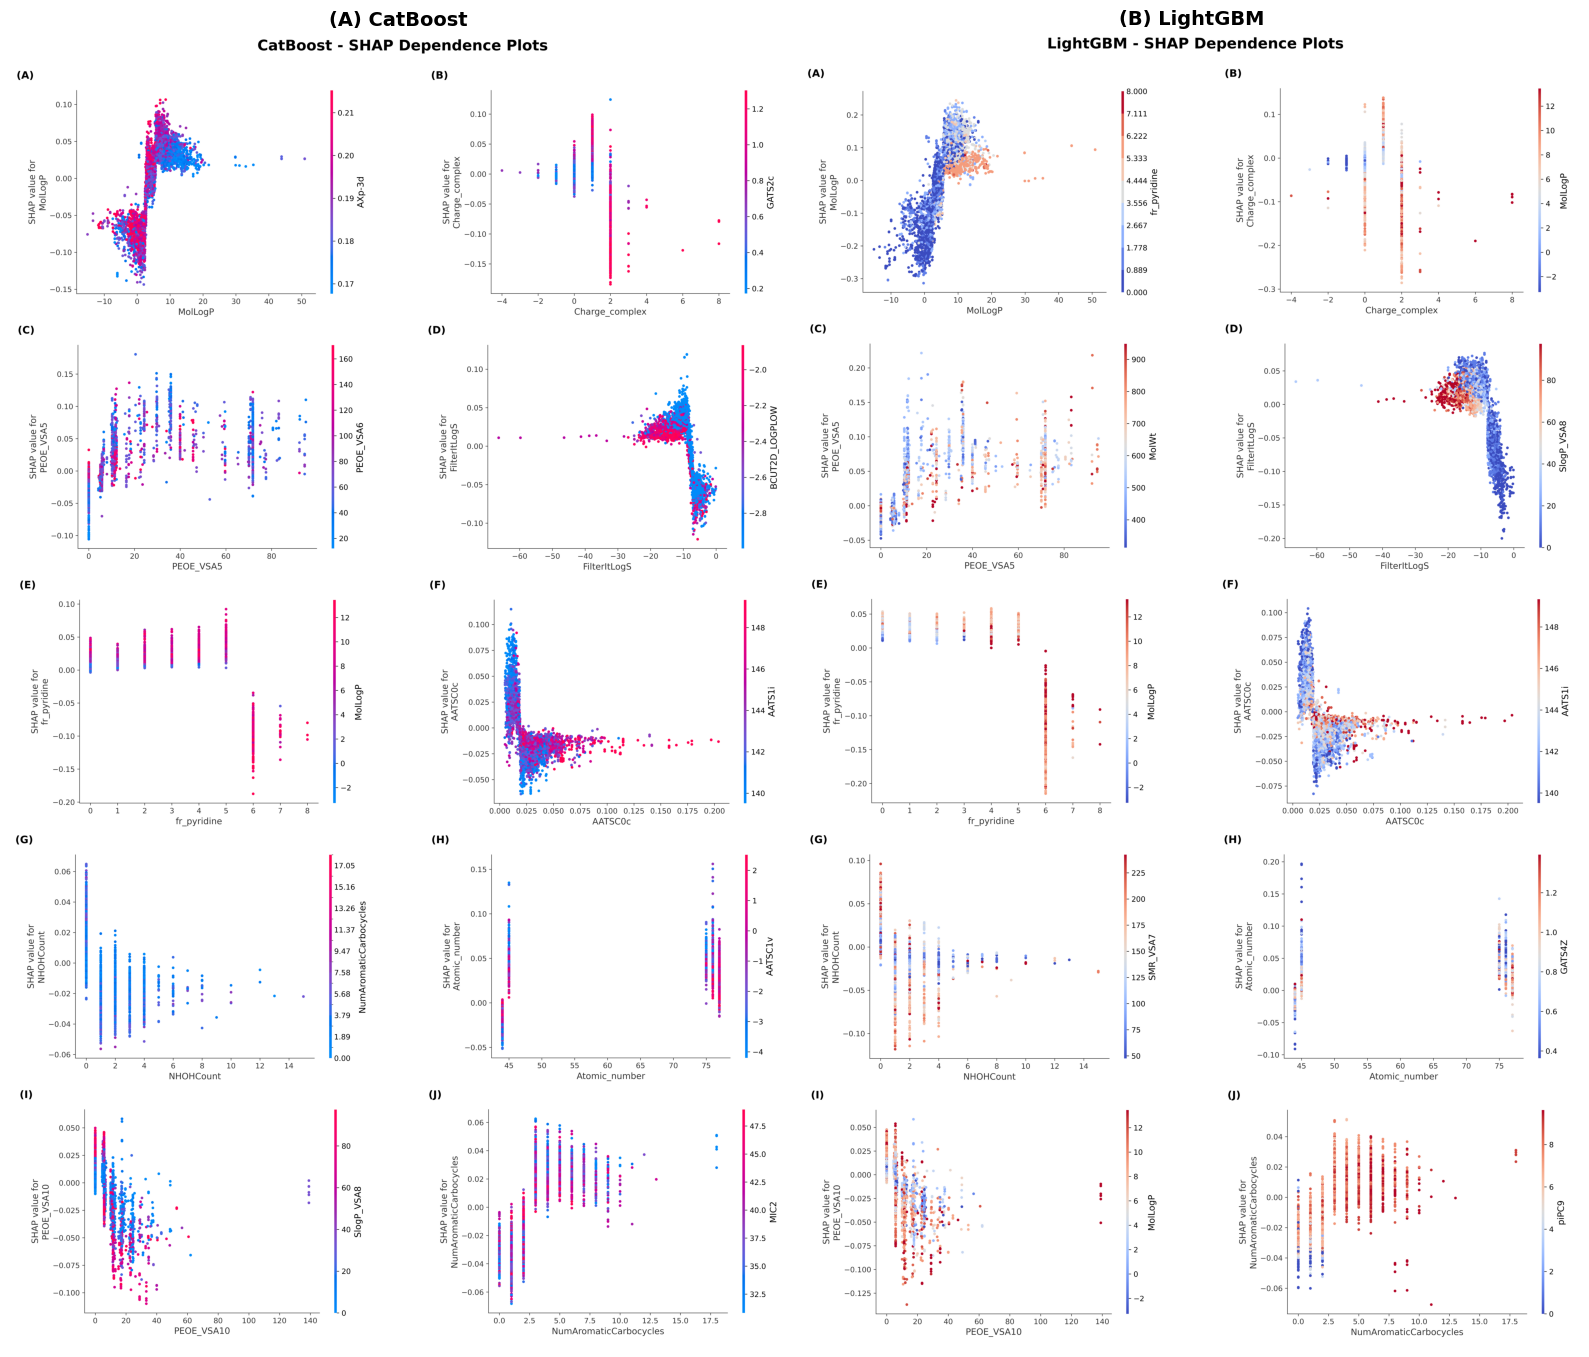

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 25))

img_cat = mpimg.imread(str(FIG_DIR / "SHAP_Dependence_combined_catboost.png"))
img_lgbm = mpimg.imread(str(FIG_DIR / "SHAP_Dependence_combined_lightgbm.png"))

axes[0].imshow(img_cat)
axes[0].axis("off")
axes[0].set_title("(A) CatBoost", fontsize=14, fontweight="bold")

axes[1].imshow(img_lgbm)
axes[1].axis("off")
axes[1].set_title("(B) LightGBM", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(str(FIG_DIR / "SHAP_Dependence_combined_of_Models.png"), dpi=600, bbox_inches="tight")
plt.show()